# Partie 2 · Étape 2 : peut-on construire un premier score ?

Le notebook 1 a montré que le **statut de défaut n'est pas expliqué par l'impayé**. On pose quand même la question qu'un analyste risque se poserait : *avec les informations connues au moment de l'octroi, peut-on prédire quels clients deviendront Douteux ou Contentieux ?*

La démarche :

1. définir **la cible** et **le périmètre** (sans les lignes aux anomalies bloquantes) ;
2. choisir **les variables**, en excluant le retard de paiement (**fuite de données**) ;
3. comparer **3 modèles lisibles** à une **référence « hasard »**, avec une validation croisée répétée ;
4. vérifier, avec un **test de permutation**, si le meilleur score fait mieux que le hasard ;
5. vérifier, avec un **contrôle positif**, que la méthode sait détecter un signal quand il existe.

## 1. Données, cible et périmètre

In [1]:
import sys
from pathlib import Path

RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RACINE))

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold, cross_val_score,
                                     cross_val_predict, permutation_test_score)
from sklearn.metrics import roc_auc_score, confusion_matrix

from src.chargement import charger_donnees
from src.controles import executer_controles, fiabiliser, STATUTS_DECLASSES, REGLES_HORS_PERIMETRE_MODELE
from src.graphiques import appliquer_style, BLEU, ORANGE, GRIS, ENCRE_2, COULEURS_GRAVITE

appliquer_style()
FIGURES, SORTIES = RACINE / "figures", RACINE / "outputs"
GRAINE = 42

In [2]:
df, _ = charger_donnees(RACINE / "data" / "dataset_BNDE.csv")
portefeuille, _ = executer_controles(df)
fiable = fiabiliser(portefeuille)

exclus = fiable.loc[fiable["Hors_Perimetre_Modele"],
                    ["Client_ID", "Revenu_Mensuel", "Montant_Credit", "Retard_Paiement_Jours", "Statut_Credit"]
                    + REGLES_HORS_PERIMETRE_MODELE]
base = fiable.loc[~fiable["Hors_Perimetre_Modele"]].copy()
base["Defaut"] = base["Statut_Corrige"].isin(STATUTS_DECLASSES).astype(int)

print(f"{len(fiable)} crédits -> {len(exclus)} exclus -> {len(base)} dans le périmètre de modélisation")
print(f"Taux de défaut (Douteux + Contentieux) : {base['Defaut'].mean():.1%}")
exclus

500 crédits -> 9 exclus -> 491 dans le périmètre de modélisation
Taux de défaut (Douteux + Contentieux) : 35.2%


,Client_ID,Revenu_Mensuel,Montant_Credit,Retard_Paiement_Jours,Statut_Credit,R01,R02,R03,R06
5,CLI0006,12000000.0,1000000,1,Bon,False,False,False,True
42,CLI0043,225000.0,95000000,9,Bon,False,False,True,False
87,CLI0088,565000.0,1000000,980,Bon,False,True,False,False
151,CLI0152,-63000.0,5000000,5,Douteux,True,False,False,False
191,CLI0192,-71000.0,10000000,38,Douteux,True,False,False,False
250,CLI0251,0.0,1000000,50,Bon,True,False,False,False
303,CLI0304,611000.0,1000000,91,Bon,False,True,False,False
436,CLI0437,-10000.0,500000,1,Douteux,True,False,False,False
445,CLI0446,-16000.0,2000000,3,Bon,True,False,False,False


- **Cible** : `Defaut = 1` si le statut (corrigé) est Douteux ou Contentieux. On regroupe les deux car 50 Contentieux, c'est trop peu pour un modèle à trois classes.
- **Périmètre** : on retire les **9 crédits** dont une valeur est impossible ou aberrante (revenus ≤ 0, montant de 95 M, revenu de 12 M) ou dont le statut était faux (les 2 crédits « Bon » à plus de 90 jours). Entraîner un modèle sur des erreurs connues, c'est lui apprendre ces erreurs.

**Limite assumée** : les 176 déclassements « à justifier » restent dans la cible, car on n'a aucun moyen de les trier. C'est justement ce que l'on teste.

## 2. Les variables : pourquoi on retire le retard de paiement

Un **score d'octroi** sert à décider d'accorder ou non un crédit. Il ne peut utiliser que ce que la banque sait **au moment de la demande** : revenu, montant, durée, taux, garantie, région, secteur, âge, nombre de crédits antérieurs.

Le **retard de paiement** n'existe qu'**après** l'octroi. En plus, il sert normalement à **définir** le statut (règle des 90 jours). Le mettre dans le modèle, c'est lui donner la réponse : c'est une **fuite de données** (*data leakage*). Le modèle aurait l'air excellent en test et serait inutilisable en vrai.

On ajoute deux variables construites :

- **`Taux_Endettement`** = mensualité / revenu : la capacité de remboursement ;
- le **logarithme** du revenu, du montant et du taux d'endettement, qui sont très asymétriques.

In [3]:
VAR_LOG = ["Revenu_Fiabilise", "Montant_Credit", "Taux_Endettement"]
VAR_NUM = ["Age", "Duree_Mois", "Taux_Interet", "Nb_Credits_Anterieurs"]
VAR_CAT = ["Region", "Secteur_Activite", "Garantie"]

X = base[VAR_LOG + VAR_NUM + VAR_CAT]
y = base["Defaut"]
X.isna().sum().loc[lambda s: s > 0].rename("Valeurs manquantes (imputées par la médiane)")

Revenu_Fiabilise    20
Taux_Endettement    30
Age                 14
Taux_Interet        10
Name: Valeurs manquantes (imputées par la médiane), dtype: int64

### Pouvoir discriminant de chaque variable prise seule

L'**AUC** mesure la capacité d'une variable (ou d'un score) à classer un mauvais payeur au-dessus d'un bon payeur :

- **0,5** = hasard pur (pile ou face) ;
- **1** = séparation parfaite ;
- en pratique, un score d'octroi bancaire utilisable a souvent une AUC de **0,7 ou plus**.

La p-value vient du test de Mann-Whitney, qui est le test statistique associé à l'AUC.

In [4]:
lignes = []
for var in VAR_LOG + VAR_NUM + ["Retard_Paiement_Jours"]:
    ok = base[var].notna()
    defaut, sain = base.loc[ok & (y == 1), var], base.loc[ok & (y == 0), var]
    lignes.append({"Variable": var,
                   "AUC": roc_auc_score(y[ok], base.loc[ok, var]),
                   "p_value": mannwhitneyu(defaut, sain).pvalue})
univarie = pd.DataFrame(lignes).round(3)
univarie

,Variable,AUC,p_value
0,Revenu_Fiabilise,0.462,0.175
1,Montant_Credit,0.489,0.692
2,Taux_Endettement,0.511,0.688
3,Age,0.476,0.392
4,Duree_Mois,0.479,0.433
5,Taux_Interet,0.524,0.391
6,Nb_Credits_Anterieurs,0.453,0.079
7,Retard_Paiement_Jours,0.537,0.180


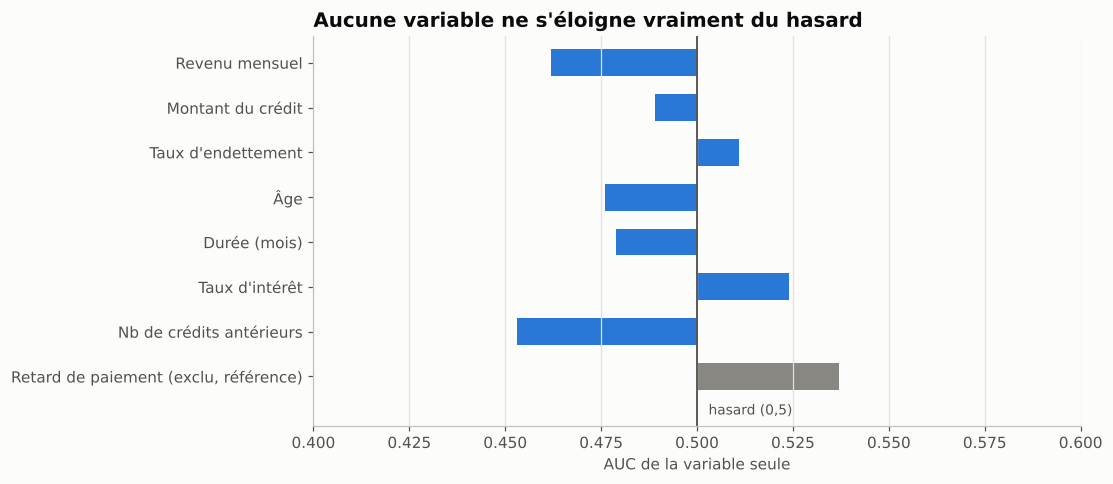

In [5]:
u = univarie.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.6))
LIBELLES = {"Revenu_Fiabilise": "Revenu mensuel", "Montant_Credit": "Montant du crédit",
            "Taux_Endettement": "Taux d'endettement", "Age": "Âge", "Duree_Mois": "Durée (mois)",
            "Taux_Interet": "Taux d'intérêt", "Nb_Credits_Anterieurs": "Nb de crédits antérieurs",
            "Retard_Paiement_Jours": "Retard de paiement (exclu, référence)"}
couleurs = [GRIS if v == "Retard_Paiement_Jours" else BLEU for v in u["Variable"]]
ax.barh(u["Variable"].map(LIBELLES), u["AUC"] - 0.5, left=0.5, color=couleurs, height=0.6)
ax.axvline(0.5, color=ENCRE_2, lw=1.2)
ax.set_xlim(0.40, 0.60)
ax.set_ylim(-1.1, len(u) - 0.4)
ax.text(0.503, -0.85, "hasard (0,5)", fontsize=9, color=ENCRE_2)
ax.set_xlabel("AUC de la variable seule")
ax.set_title("Aucune variable ne s'éloigne vraiment du hasard")
ax.grid(axis="y", visible=False)
fig.savefig(FIGURES / "06_auc_univariee.png")
plt.show()

**Lecture.** Toutes les AUC sont comprises entre **0,45 et 0,54**. Aucune p-value ne passe sous 0,05.

Le **nombre de crédits antérieurs** est la variable la plus « prometteuse » (les clients déjà connus font un peu moins défaut), mais l'effet est faible et non significatif.

Détail révélateur : **même le retard de paiement, censé définir le statut, ne le prédit pas** (AUC 0,54). Cela confirme le notebook 1.

## 3. Trois modèles contre le hasard

On compare quatre modèles :

- **Référence (hasard)** : donne la même probabilité à tout le monde, donc une AUC de 0,5 par construction ;
- **Régression logistique** : le standard des scores bancaires, lisible coefficient par coefficient ;
- **Arbre de décision** (profondeur 3) : des règles « si... alors » faciles à expliquer à un comité crédit ;
- **Forêt aléatoire** : plus flexible, elle capte des combinaisons non linéaires. Elle sert de test : si elle ne trouve rien non plus, ce n'est pas un problème de modèle.

**Validation** : validation croisée stratifiée à 5 blocs, répétée 10 fois, soit 50 mesures d'AUC par modèle. Avec 491 lignes, un simple découpage apprentissage / test donnerait un résultat qui dépend beaucoup du hasard du découpage.

Le prétraitement (imputation, log, standardisation, encodage) est **dans le pipeline** : il est recalculé sur chaque bloc d'apprentissage, sans regarder le bloc de test.

In [6]:
def preprocesseur(var_log=VAR_LOG, var_num=VAR_NUM, var_cat=VAR_CAT):
    log = make_pipeline(SimpleImputer(strategy="median"),
                        FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler())
    num = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
    cat = OneHotEncoder(handle_unknown="ignore")
    return ColumnTransformer([("log", log, var_log), ("num", num, var_num), ("cat", cat, var_cat)])


MODELES = {
    "Référence (hasard)": DummyClassifier(strategy="prior"),
    "Régression logistique": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Arbre de décision": DecisionTreeClassifier(max_depth=3, min_samples_leaf=20,
                                                class_weight="balanced", random_state=GRAINE),
    "Forêt aléatoire": RandomForestClassifier(n_estimators=300, min_samples_leaf=10, class_weight="balanced",
                                              random_state=GRAINE, n_jobs=-1),
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=GRAINE)

scores = {nom: cross_val_score(Pipeline([("prep", preprocesseur()), ("modele", m)]), X, y,
                               cv=cv, scoring="roc_auc", n_jobs=-1)
          for nom, m in MODELES.items()}

resultats = pd.DataFrame({
    "AUC_moyenne": {k: s.mean() for k, s in scores.items()},
    "Ecart_type": {k: s.std() for k, s in scores.items()},
    "AUC_p2.5": {k: np.percentile(s, 2.5) for k, s in scores.items()},
    "AUC_p97.5": {k: np.percentile(s, 97.5) for k, s in scores.items()},
})
resultats["Gini"] = 2 * resultats["AUC_moyenne"] - 1
resultats = resultats.round(3)
resultats

,AUC_moyenne,Ecart_type,AUC_p2.5,AUC_p97.5,Gini
Référence (hasard),0.500,0.000,0.500,0.500,0.000
Régression logistique,0.499,0.055,0.376,0.574,-0.002
Arbre de décision,0.503,0.047,0.411,0.576,0.007
Forêt aléatoire,0.504,0.058,0.378,0.603,0.008


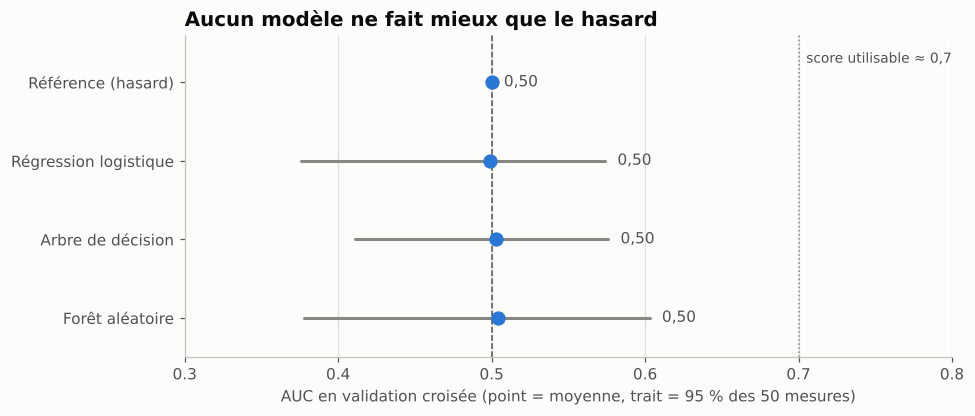

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.8))
noms = list(resultats.index)[::-1]
for i, nom in enumerate(noms):
    r = resultats.loc[nom]
    ax.plot([r["AUC_p2.5"], r["AUC_p97.5"]], [i, i], color=GRIS, lw=2, solid_capstyle="round")
    ax.scatter(r["AUC_moyenne"], i, s=70, color=BLEU, zorder=3)
    ax.text(r["AUC_p97.5"] + 0.008, i, f"{r['AUC_moyenne']:.2f}".replace(".", ","), va="center",
            fontsize=10, color=ENCRE_2)
ax.axvline(0.5, color=ENCRE_2, lw=1, ls="--")
ax.axvline(0.7, color=COULEURS_GRAVITE["Information"], lw=1, ls=":")
ax.text(0.705, len(noms) - 0.75, "score utilisable ≈ 0,7", fontsize=9, color=ENCRE_2)
ax.set_yticks(range(len(noms)), noms)
ax.set_ylim(-0.5, len(noms) - 0.4)
ax.set_xlim(0.3, 0.8)
ax.set_xlabel("AUC en validation croisée (point = moyenne, trait = 95 % des 50 mesures)")
ax.set_title("Aucun modèle ne fait mieux que le hasard")
ax.grid(axis="y", visible=False)
fig.savefig(FIGURES / "07_auc_modeles.png")
plt.show()

**Lecture.** Les trois modèles obtiennent une AUC moyenne de **0,50**, exactement comme la référence. Leurs intervalles sont larges (de 0,38 à 0,60) et centrés sur le hasard. Le **Gini**, l'indicateur que les banques utilisent souvent (Gini = 2 × AUC − 1), est **nul**.

La forêt aléatoire ne fait pas mieux que la régression logistique. Le problème ne vient donc pas d'un modèle trop simple : **il n'y a pas de signal à capter**.

## 4. Test de permutation : le score est-il meilleur que le hasard ?

On mélange **au hasard** la colonne `Defaut` 500 fois, en cassant tout lien réel entre variables et statut, et on recalcule l'AUC à chaque fois. On obtient ainsi la distribution des AUC qu'on obtiendrait **par pur hasard**.

Si l'AUC du vrai modèle sort nettement de cette distribution, le modèle a appris quelque chose de réel.

In [8]:
regression = Pipeline([("prep", preprocesseur()),
                       ("modele", LogisticRegression(max_iter=1000, class_weight="balanced"))])
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=GRAINE)
auc_reelle, auc_permutees, p_value = permutation_test_score(
    regression, X, y, cv=cv5, scoring="roc_auc", n_permutations=500, random_state=GRAINE, n_jobs=-1)
print(f"AUC du modèle : {auc_reelle:.3f}")
print(f"AUC obtenues par hasard : médiane {np.median(auc_permutees):.3f}, "
      f"95 % entre {np.percentile(auc_permutees, 2.5):.3f} et {np.percentile(auc_permutees, 97.5):.3f}")
print(f"p-value : {p_value:.2f}")

AUC du modèle : 0.501
AUC obtenues par hasard : médiane 0.503, 95 % entre 0.425 et 0.571
p-value : 0.52


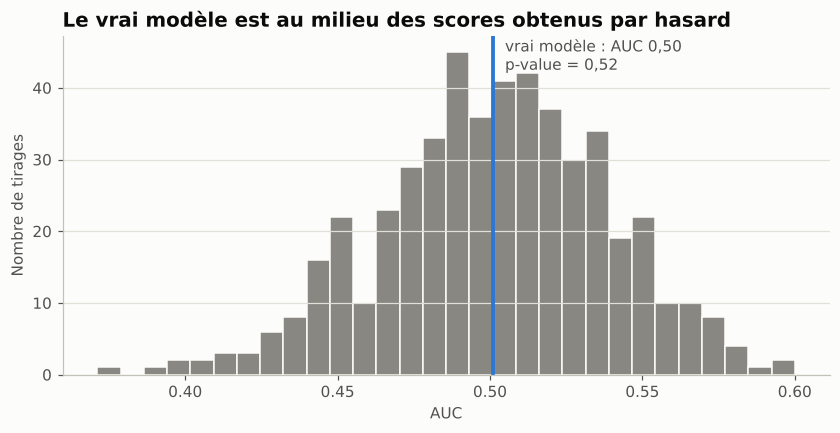

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(auc_permutees, bins=30, color=GRIS, edgecolor="#fcfcfb", linewidth=1)
ax.axvline(auc_reelle, color=BLEU, lw=2.5)
ax.text(auc_reelle + 0.004, ax.get_ylim()[1] * 0.9,
        f"vrai modèle : AUC {auc_reelle:.2f}\np-value = {p_value:.2f}".replace(".", ","), fontsize=10, color=ENCRE_2)
ax.set_xlabel("AUC")
ax.set_ylabel("Nombre de tirages")
ax.set_title("Le vrai modèle est au milieu des scores obtenus par hasard")
ax.grid(axis="x", visible=False)
fig.savefig(FIGURES / "08_test_permutation.png")
plt.show()

**Lecture.** L'AUC du vrai modèle tombe **au milieu** des AUC obtenues en mélangeant les statuts au hasard. Une p-value d'environ 0,5 signifie qu'un statut tiré à pile ou face donnerait un score au moins aussi bon une fois sur deux.

Conclusion statistique : **on ne peut pas distinguer ce score du hasard.**

## 5. Contrôle positif : la méthode marche-t-elle ?

Un résultat nul peut venir des données... ou d'une erreur dans la méthode. Pour trancher, on fabrique une **cible simulée** dont on connaît la réponse : le risque de défaut augmente avec le taux d'endettement, avec le même taux de défaut moyen (~35 %).

Si le même pipeline retrouve ce signal, la méthode est validée, et le résultat nul vient bien des données réelles.

In [10]:
rng = np.random.default_rng(GRAINE)
z = np.log(base["Taux_Endettement"].fillna(base["Taux_Endettement"].median()))
z = (z - z.mean()) / z.std()
proba_simulee = 1 / (1 + np.exp(-(-0.75 + 1.0 * z)))
y_simule = pd.Series((rng.uniform(size=len(z)) < proba_simulee).astype(int), index=base.index)

auc_simule = cross_val_score(regression, X, y_simule, cv=cv, scoring="roc_auc", n_jobs=-1)
print(f"Taux de défaut simulé : {y_simule.mean():.1%}")
print(f"AUC sur la cible simulée : {auc_simule.mean():.2f} (± {auc_simule.std():.2f})")
print(f"AUC sur la vraie cible   : {scores['Régression logistique'].mean():.2f}")

Taux de défaut simulé : 34.8%
AUC sur la cible simulée : 0.69 (± 0.04)
AUC sur la vraie cible   : 0.50


**Lecture.** Sur la cible simulée, le même pipeline obtient une AUC d'environ **0,7** : il détecte le signal quand il existe. **La méthode n'est pas en cause.**

## 6. Ce qu'il ne faut pas faire : lire les coefficients d'un modèle sans signal

Un modèle sans pouvoir prédictif produit quand même des coefficients et des règles. Les présenter comme des « facteurs de risque » serait une erreur.

In [11]:
regression.fit(X, y)
noms = regression["prep"].get_feature_names_out()
coefs = pd.DataFrame({"Variable": [n.split("__", 1)[1] for n in noms],
                      "Coefficient": regression["modele"].coef_[0]})
coefs["Odds_ratio"] = np.exp(coefs["Coefficient"])
coefs.reindex(coefs["Coefficient"].abs().sort_values(ascending=False).index).head(8).round(2)

,Variable,Coefficient,Odds_ratio
20,Garantie_Non renseignée,-0.40,0.67
13,Secteur_Activite_BTP,-0.36,0.70
14,Secteur_Activite_Commerce,0.27,1.31
18,Garantie_Immobilière,0.26,1.30
8,Region_Kaolack,-0.21,0.81
6,Nb_Credits_Anterieurs,-0.16,0.86
5,Taux_Interet,0.10,1.10
0,Revenu_Fiabilise,-0.09,0.91


In [12]:
# Stabilité de l'arbre : quelle variable choisit-il en premier, sur 30 échantillons bootstrap ?
racines = []
for i in range(30):
    idx = rng.choice(len(X), size=len(X), replace=True)
    arbre = Pipeline([("prep", preprocesseur()),
                      ("modele", DecisionTreeClassifier(max_depth=3, min_samples_leaf=20,
                                                        class_weight="balanced", random_state=i))])
    arbre.fit(X.iloc[idx], y.iloc[idx])
    noms_arbre = arbre["prep"].get_feature_names_out()
    racines.append(noms_arbre[arbre["modele"].tree_.feature[0]].split("__", 1)[1])
pd.Series(racines).value_counts().rename("Nb de fois en 1re règle (sur 30)").to_frame()

,Nb de fois en 1re règle (sur 30)
Taux_Interet,16
Revenu_Fiabilise,4
Age,3
Nb_Credits_Anterieurs,2
Taux_Endettement,2
Montant_Credit,1
Garantie_Non renseignée,1
Secteur_Activite_BTP,1


**Lecture.** Les coefficients semblent raconter une histoire : une garantie non renseignée ou le secteur BTP « protégeraient » du défaut, le commerce l'aggraverait... C'est d'ailleurs ce que suggérait la partie 1 pour les clients sans garantie. Mais cette histoire n'est pas robuste.

La preuve : sur 30 échantillons légèrement différents, **l'arbre ne prend le taux d'intérêt comme première règle qu'une fois sur deux**, et choisit 7 autres variables le reste du temps. Une règle qui change dès qu'on modifie quelques clients décrit le bruit, pas le risque.

## 7. Ce que donnerait ce score en production

On simule la décision : chaque client est évalué par un modèle qui ne l'a jamais vu (prédiction en validation croisée).

In [13]:
pred = cross_val_predict(regression, X, y, cv=cv5)
mc = pd.DataFrame(confusion_matrix(y, pred), index=["Réel : bon payeur", "Réel : défaut"],
                  columns=["Prédit : bon payeur", "Prédit : défaut"])
detection = mc.iloc[1, 1] / mc.iloc[1].sum()
fausses_alertes = mc.iloc[0, 1] / mc.iloc[0].sum()
print(f"Défauts détectés : {detection:.0%}   |   Bons payeurs refusés à tort : {fausses_alertes:.0%}")
mc

Défauts détectés : 46%   |   Bons payeurs refusés à tort : 48%


,Prédit : bon payeur,Prédit : défaut
Réel : bon payeur,165,153
Réel : défaut,93,80


**Lecture.** Le score repère environ **46 % des défauts**, mais en refusant aussi **48 % des bons payeurs**. C'est l'équivalent d'un tirage à pile ou face : l'utiliser pour décider d'un octroi ferait perdre de bons clients sans réduire le risque.

In [14]:
resultats_export = resultats.copy()
resultats_export.loc["Régression logistique", "p_value_permutation"] = round(p_value, 3)
resultats_export.loc["Contrôle positif (cible simulée)", "AUC_moyenne"] = round(auc_simule.mean(), 3)
resultats_export.to_csv(SORTIES / "resultats_modeles.csv", sep=";", encoding="utf-8-sig", decimal=",")
resultats_export

,AUC_moyenne,Ecart_type,AUC_p2.5,AUC_p97.5,Gini,p_value_permutation
Référence (hasard),0.500,0.000,0.500,0.500,0.000,NaN
Régression logistique,0.499,0.055,0.376,0.574,-0.002,0.519
Arbre de décision,0.503,0.047,0.411,0.576,0.007,NaN
Forêt aléatoire,0.504,0.058,0.378,0.603,0.008,NaN
Contrôle positif (cible simulée),0.695,NaN,NaN,NaN,NaN,NaN


## 8. Conclusion : fiabiliser d'abord, le score ensuite

**Réponse à la question posée en partie 1** : sur ce portefeuille, il faut **commencer par fiabiliser les données**. Ce n'est pas une préférence de méthode, c'est le résultat des tests :

1. Le statut de défaut **n'est pas expliqué par l'impayé** : 176 déclassements sur 176 se font sans impayé de plus de 90 jours (notebook 1).
2. **Aucun modèle ne fait mieux que le hasard** (AUC 0,50, Gini 0, p-value du test de permutation ≈ 0,5).
3. La méthode, elle, **fonctionne** : elle retrouve un signal simulé (AUC ≈ 0,7).

Le problème est donc dans la **cible** et dans les **données disponibles**, pas dans le modèle.

### Ce qu'il faudrait pour construire un vrai score

| Donnée à collecter | Pourquoi |
|---|---|
| **Motif et date de déclassement** | Pour savoir si le statut est un jugement fondé ou une erreur, et dater le défaut |
| **Date d'octroi, encours restant dû, échéancier** | Pour définir une cible propre (ex. : impayé > 90 jours dans les 12 mois suivant l'octroi) et calculer les provisions réelles |
| **Historique des remboursements** | Pour construire un score **comportemental** (qui, lui, peut utiliser les retards passés) |
| **Données du bureau d'information sur le crédit (BIC)** | Pour connaître l'endettement total du client, pas seulement chez cette banque |
| **TEG réel, valeur et rang des garanties** | Pour les contrôles de conformité et le calcul des pertes en cas de défaut |

### Suite possible

- **Partie 3** : rejouer `src/controles.py` sur un portefeuille avec les données ci-dessus, définir une cible à 12 mois, puis construire une **grille de score** (points par caractéristique), comme dans les banques.